In [1]:

from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.tsa.api as smt

In [2]:
# аналогичным образом загружаем данные о пассажирах
ecg = pd.read_csv('data/calm_p.csv')
# неподходящий формат данных приводим к тому, с которым Pandas может работать

df = ecg.set_index('Time').sort_index()

### Скользящее среднее

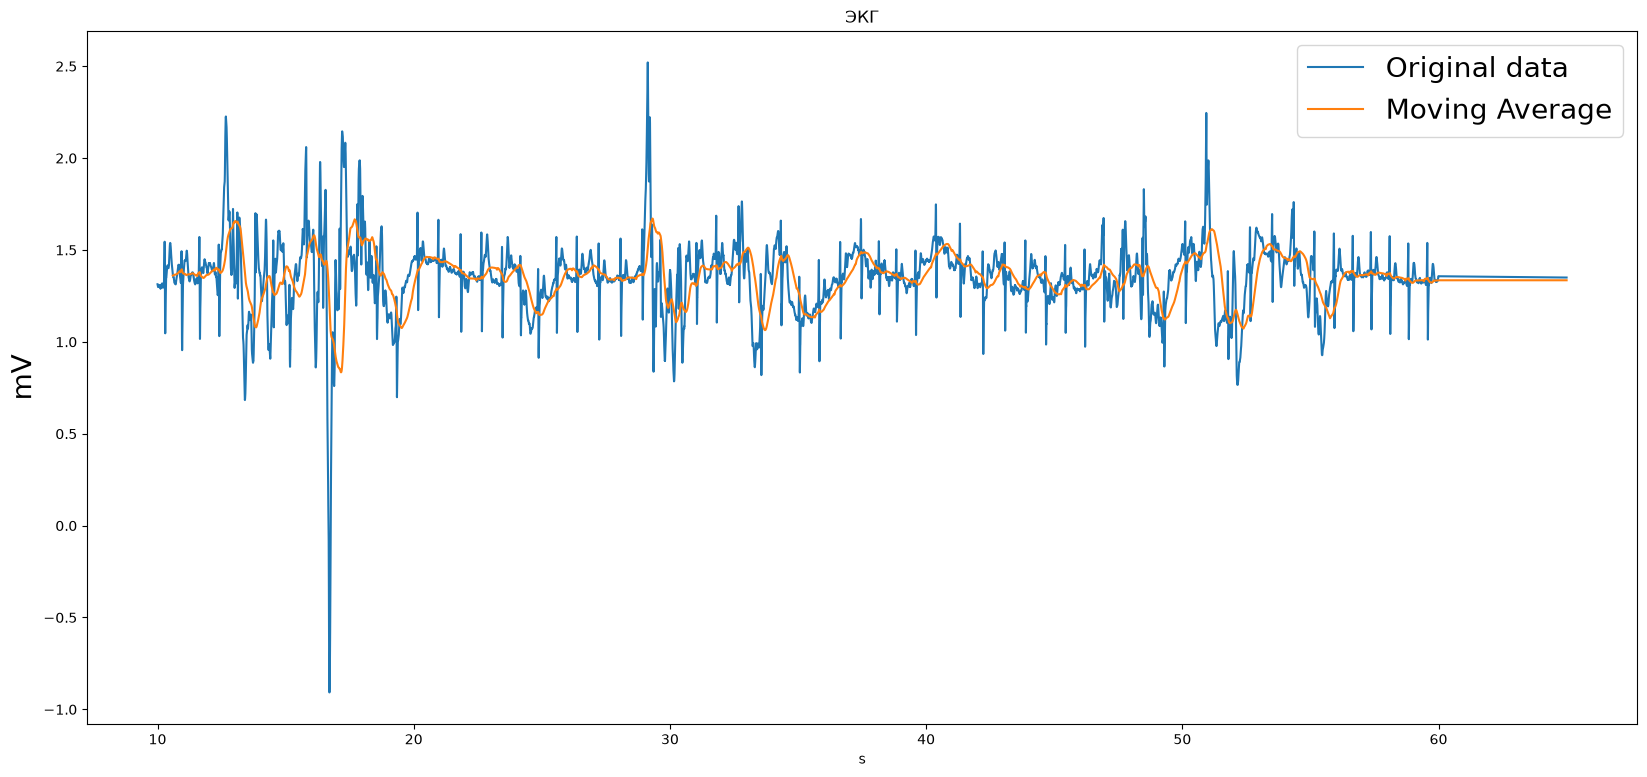

In [3]:
df['MA_window_6'] = df['1'].rolling(window=600).mean()
fig = plt.figure(figsize=(20, 9))
plt.plot(df['1'], label='Original data')
plt.plot(df['MA_window_6'], label='Moving Average')
plt.legend(fontsize="20")
plt.title('ЭКГ')
plt.ylabel('mV', fontsize="20")
plt.xlabel('s')
plt.show()


Давайте напишем функцию, которая поможет нам понять тенденцию и движения временного ряда. Мы хотим видеть на графике некоторую скользящую статистику, такую как:

M скользящее среднее: невзвешенное среднее предыдущих n данных (также называемое скользящим средним).

Полосы Боллинджера: верхняя полоса в k раз на n -периодное стандартное отклонение выше скользящей средней и нижняя полоса в k раз на стандартное отклонение N ниже.

In [4]:
'''
Отрисовка скользящего среднего по медиане для ts с 95% доверительным интервалом для стандартного отклонения.
:parameter
  :param ts: датасет
  :param window: кол-во семплов в окне - для скользящих средних
  :param plot_ma: bool - whether plot moving average
  :param plot_intervals: bool - whether plot upper and lower bounds
'''
def plot_ts(ts, plot_ma=True, plot_intervals=True, window=100,
            figsize=(15,5)):
    rolling_mean = ts.rolling(window=window).mean()
    rolling_std = ts.rolling(window=window).std()
    plt.figure(figsize=figsize)
    plt.title(ts.name)
    plt.plot(ts[window:], label='Реальные значения', color="black")
    if plot_ma:
        plt.plot(rolling_mean, 'g', label='MA'+str(window),
                 color="red")
    if plot_intervals:
        lower_bound = rolling_mean - (1.96 * rolling_std)
        upper_bound = rolling_mean + (1.96 * rolling_std)
    plt.fill_between(x=ts.index, y1=lower_bound, y2=upper_bound,
                     color='lightskyblue', alpha=0.4)
    plt.legend(loc='best')
    plt.grid(True)
    plt.show()

C:\Users\zuben\AppData\Local\Temp\ipykernel_7580\3736708662.py:17: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "g" (-> color=(0.0, 0.5, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(rolling_mean, 'g', label='MA'+str(window),


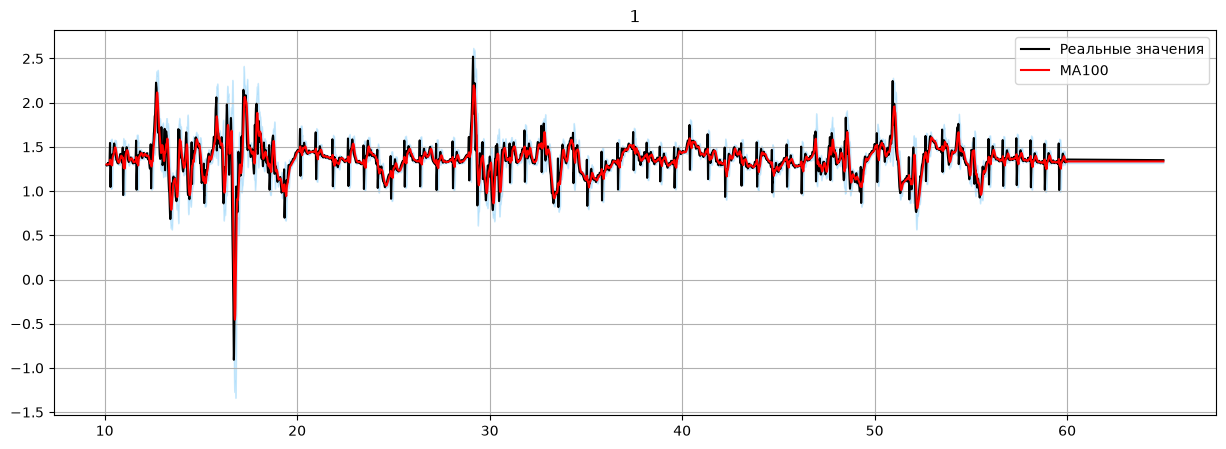

In [5]:
plot_ts(df["1"], window=100)

### ARMA

In [6]:
from statsmodels.tsa.arima.model import ARIMA

## Предсказание ряда на основе предыдущих значений

### ARIMA  

Модель авторегрессии скользящего среднего и систематический подход к её построению предназначена для анализа стационарных временных рядов на основе оценки линейной зависимости прогнозируемых значений от исторических.

Для использования модели временной ряд должен быть стационарным, т.е. его среднее и дисперсия должны быть постоянны.

Модель Бокса-Дженкинса предполагает, что временной ряд содержит три составляющие: авторегресионную, интегрированную и скользящее среднее, которые в модели обозначены $p$, $d$ и $q$ соответственно:

* Величина $p$ называется порядком авторегрессии. Она позволяет ответить на вопрос, будет ли очередной элемент ряда близок к значению $X$, если к нему были близки $p$ предыдущих значений.
* Величину $d$ называют порядком интегрирования. Она показывает, насколько элемент ряда близок по значению к $d$ предыдущим значениям, если разность между ними минимальна.

* Параметр $q$— порядок скользящего среднего. Позволяет установить погрешность модели как линейную комбинацию наблюдавшихся ранее значений ошибок.

Авторегрессия — это составляющая модели временного ряда, в которой его прогнозируемое значение может быть выражено в виде линейной комбинации исторических значений этого же ряда и случайной ошибки.

Обычно модель упоминается, как ARIMA$(p,d,q)$, где $p$, $d$ и $q$ — целые неотрицательные числа, характеризующие порядок для частей модели (соответственно авторегрессионной, интегрированной и скользящего среднего).

Для временного ряда $X(t)$ модель может быть записана в виде:

$$(\delta^dX_t)=\sum^p_{t=1}a_t(\delta^dX_{t-1}) + \epsilon_t + \sum^q_{j=1}b_j(\delta^d\epsilon_{t-j})$$

где

* $\delta^d$ — оператор разности порядка $d$ (последовательное взятие $d$ раз разностей первого порядка — сначала от самого ряда, затем от полученных разностей первого порядка, затем от второго порядка и т. д.);
* $a_t$— коэффициенты авторегрессионной части модели, $\epsilon_t$— значения ошибки (полагаются независимыми одинаково распределёнными случайными величинами из нормального распределения с нулевым средним);
* $b_j$ — коэффициенты скользящего среднего.

Модель Бокса-Дженкинса широко применяются при прогнозировании временных рядов. Основная задача при этом заключается в оценке параметров модели. Методология построения ARIMA-модели исследуемого временного ряда включает следующие основные этапы:

* построение пробной модели;
* оценивание параметров модели и проверка адекватности модели;
* использование модели для прогнозирования.

Чтобы построить модель ARMA, мы можем использовать функцию ARIMA (которая будет
объяснена в следующем разделе) в statsmodels.tsa.arima.model и указать
гиперпараметр — order(p, d, q). Когда d = 0, он работает как модель ARMA.

In [7]:
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings("ignore")

X = ecg['1'].values
size = int(len(X) * 0.66)

# Берем последние 1000 точек для трейна (для скорости)
train = X[size-1000:size] 
test = X[size:]
test_subset = test[:50] # 50 шагов для теста

history = list(train)
arma_predictions = []

print("Начинаем быстрый walk-forward...")
for t in range(len(test_subset)):
    model = ARIMA(history, order=(5, 1, 0))
    model_fit = model.fit()
    yhat = model_fit.forecast()[0]
    arma_predictions.append(yhat)
    obs = test_subset[t]
    history.append(obs)
    
    if t % 10 == 0:
        print(f"Шаг {t} из {len(test_subset)} завершен.")

print("Прогноз завершен!")

Начинаем быстрый walk-forward...
Шаг 0 из 50 завершен.
Шаг 10 из 50 завершен.
Шаг 20 из 50 завершен.
Шаг 30 из 50 завершен.
Шаг 40 из 50 завершен.
Прогноз завершен!


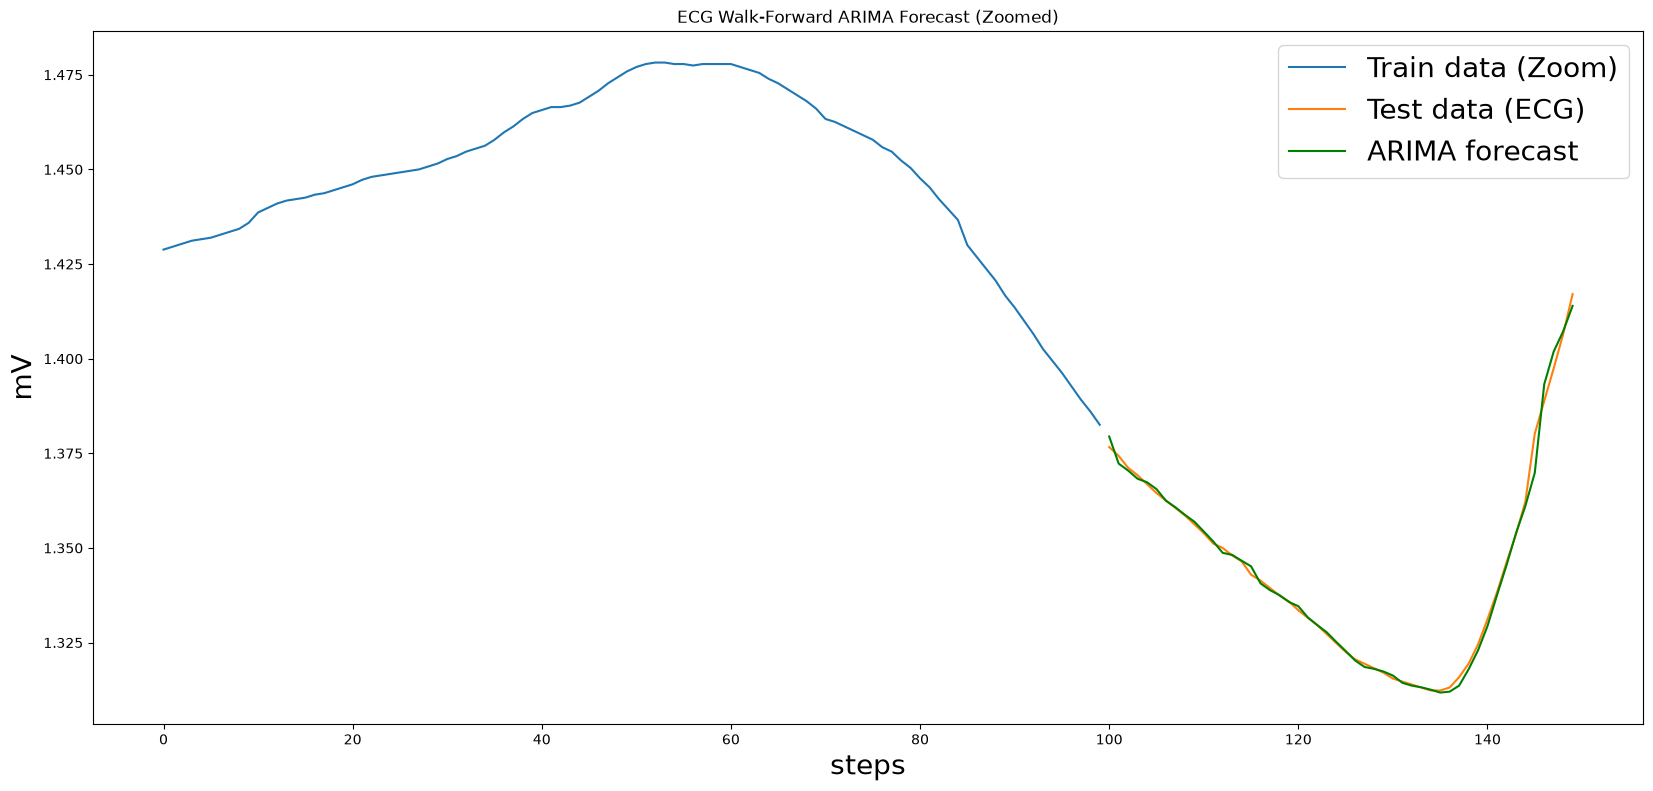

In [8]:
fig = plt.figure(figsize=(20, 9))
dur = len(arma_predictions)

zoom = 100
train_zoom = train[-zoom:]

plt.plot(range(len(train_zoom)), train_zoom, label='Train data (Zoom)')
plt.plot(range(len(train_zoom), len(train_zoom) + dur), test_subset, label='Test data (ECG)')
plt.plot(range(len(train_zoom), len(train_zoom) + dur), arma_predictions, label='ARIMA forecast', color='green')

plt.legend(fontsize="20")
plt.title('ECG Walk-Forward ARIMA Forecast (Zoomed)')
plt.ylabel('mV', fontsize="20")
plt.xlabel('steps', fontsize="20")
plt.show()

In [9]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Метрики качества прогноза ЭКГ (на тестовой выборке):")
print(f"RMSE: {np.sqrt(mean_squared_error(test_subset, arma_predictions)):.4f}")
print(f"MAE:  {mean_absolute_error(test_subset, arma_predictions):.4f}")
print(f"R2:   {r2_score(test_subset, arma_predictions):.4f}")

Метрики качества прогноза ЭКГ (на тестовой выборке):
RMSE: 0.0020
MAE:  0.0011
R2:   0.9941


### ARIMA

In [13]:
import pandas as pd

# Загружаем данные о пассажирах
passengers = pd.read_csv('data/passengers.csv')
passengers['Month'] = pd.to_datetime(passengers['Month'])
pdf = passengers.set_index('Month').sort_index()

In [14]:
arima_model = ARIMA(pdf['Passengers'], order=(10,2,10))
arima_model_fit = arima_model.fit()

In [15]:
print(arima_model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:               ARIMA(10, 2, 10)   Log Likelihood                -555.051
Date:                Thu, 05 Nov 2026   AIC                           1152.102
Time:                        20:08:35   BIC                           1214.174
Sample:                    01-01-1949   HQIC                          1177.325
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0738      0.062      1.196      0.232      -0.047       0.195
ar.L2         -1.0001      0.082    -12.219      0.000      -1.161      -0.840
ar.L3          0.0154      0.094      0.164      0.8

Полезным может быть получение линейного графика остаточных ошибок, что позволяет предположить, что некоторая информация о тенденциях все еще может быть не учтена моделью.

<Axes: xlabel='Month'>

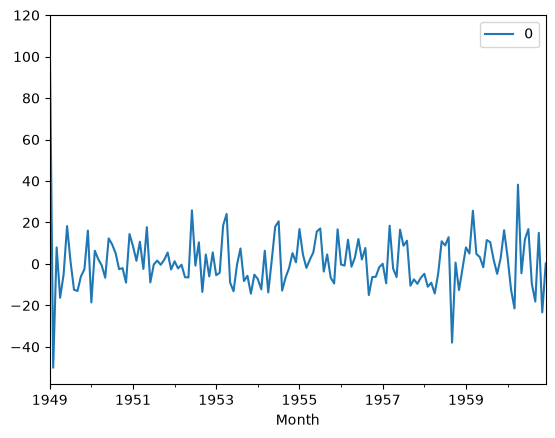

In [16]:
arima_residuals = pd.DataFrame(arima_model_fit.resid)
arima_residuals.plot()

Осуществляем предсказание

In [17]:
# forecast предсказывает только следующее значение
output = arima_model_fit.forecast()

In [18]:
X = pdf['Passengers'].values
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
arima_predictions = list()
# walk-forward validation
for t in range(len(test)):
    arima_model = ARIMA(history, order=(10,2,5))
    arima_model_fit = arima_model.fit()
    output = arima_model_fit.forecast()
    yhat = output[0]
    arima_predictions.append(yhat)
    obs = test[t]
    history.append(obs)

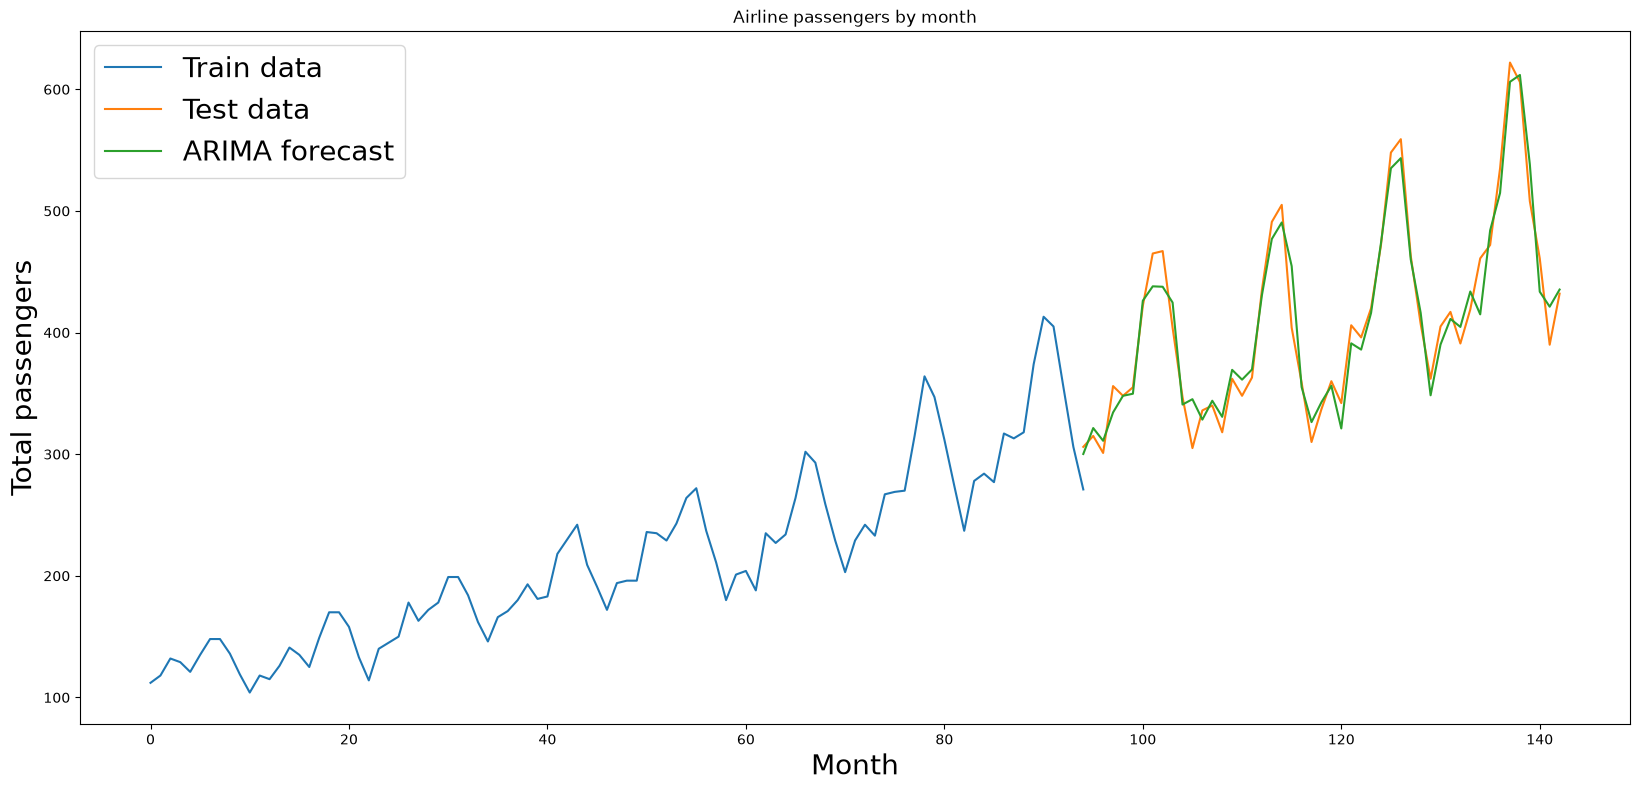

In [19]:
fig = plt.figure(figsize=(20, 9))
plt.plot([i for i in range(0, size)], train, label='Train data')
plt.plot([i for i in range(size - 1, len(X) - 1)], test, label='Test data')
plt.plot([i for i in range(size - 1, len(X) - 1)], arima_predictions, label='ARIMA forecast')
plt.legend(fontsize="20")
plt.title('Airline passengers by month')
plt.ylabel('Total passengers', fontsize="20")
plt.xlabel('Month', fontsize="20")
plt.show()

Сравним значения ARMA и ARIMA

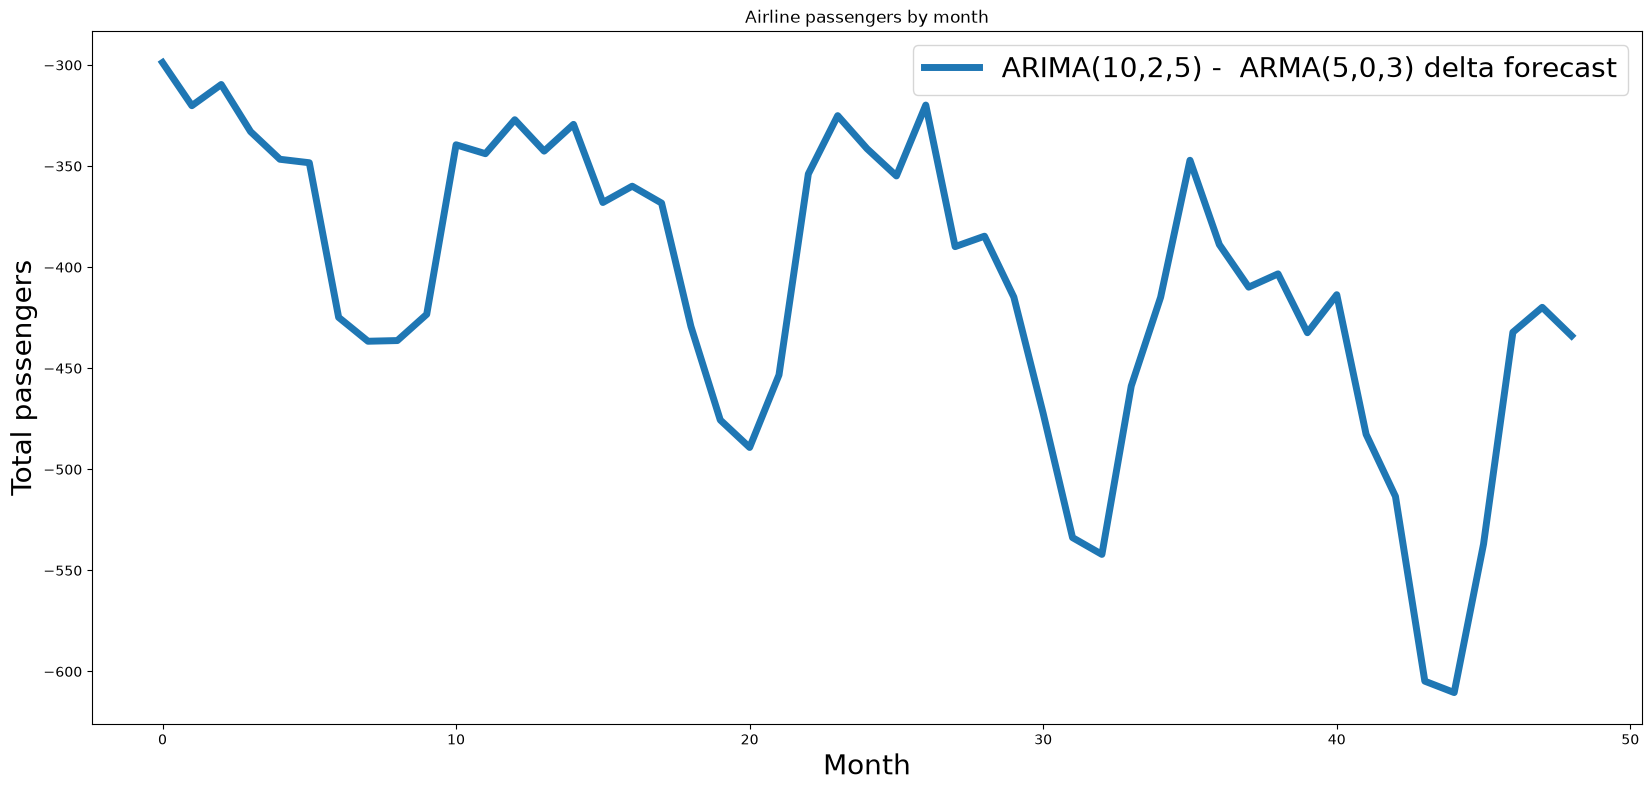

In [20]:
fig = plt.figure(figsize=(20, 9))

delta = []

for i in range(len(arima_predictions)):
    delta.append(arma_predictions[i] - arima_predictions[i])

plt.plot(delta, label='ARIMA(10,2,5) -  ARMA(5,0,3) delta forecast', linewidth=5)
plt.legend(fontsize="20")
plt.title('Airline passengers by month')
plt.ylabel('Total passengers', fontsize="20")
plt.xlabel('Month', fontsize="20")
plt.show()

### Работа с пропусками данных

* Заполнение средним и медианой​
* Заполнение предыдущим и последующим значениями​
* Заполнение скользящим средним и медианой​
* Заполнение с помощью предсказания моделей машинного обучения​
* Интерполяция

Заполнение средним и медианой

<Axes: xlabel='Month'>

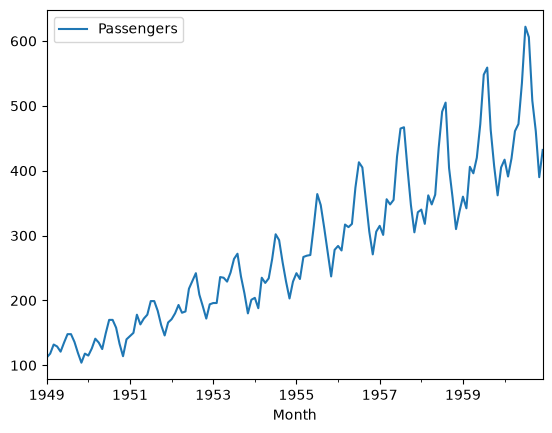

In [21]:
o_df = pdf.copy()

o_df["Passengers"][50:55] = np.nan

o_df.plot()

Заполнение скользящим средним и медианой​

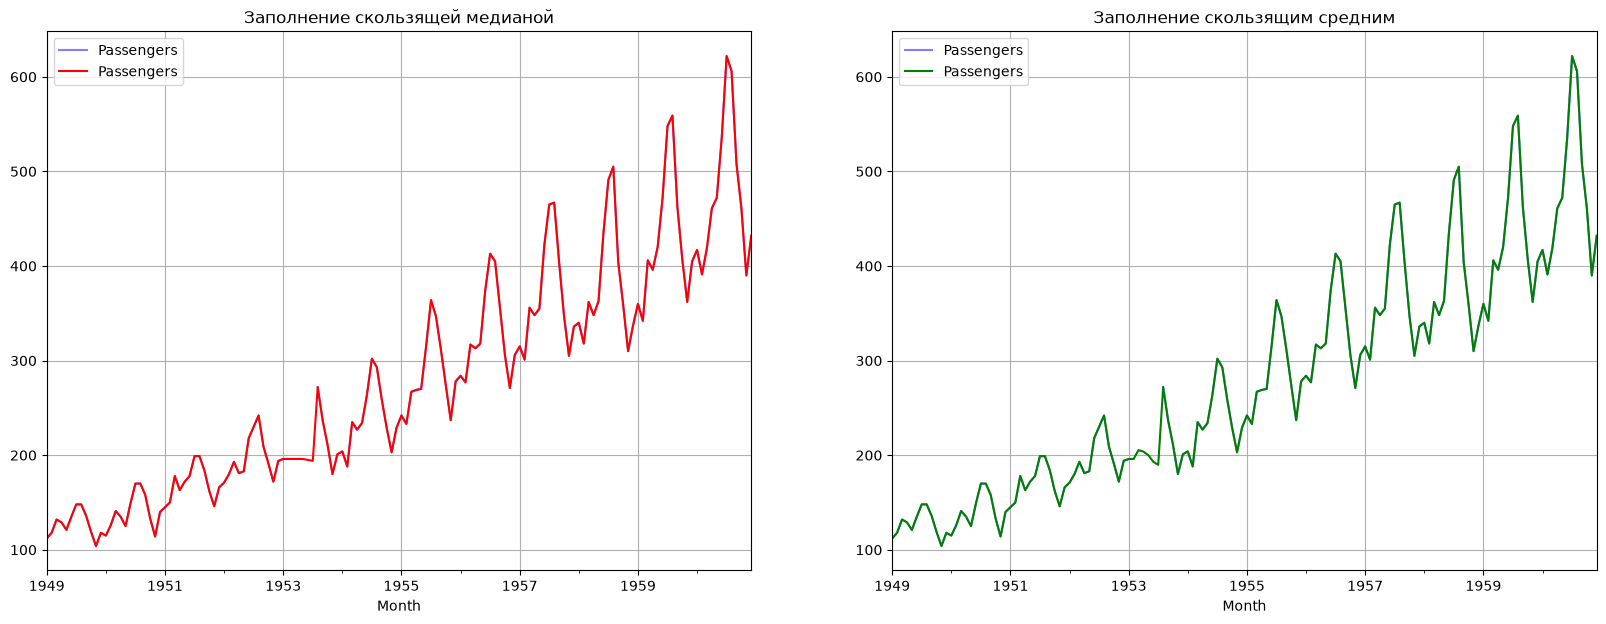

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Создаем базовый ряд с пропусками
base_df = pdf.copy()
# Обращаемся по правильному индексу (в данном случае просто по позиции)
base_df.iloc[50:55, 0] = np.nan 

# 2. Метод скользящей медианы на независимой копии
df_rolling_median = base_df.copy()
roll_median = df_rolling_median["Passengers"].rolling(window=10, min_periods=1).median()
df_rolling_median["Passengers"] = df_rolling_median["Passengers"].fillna(roll_median)

# 3. Метод скользящего среднего на независимой копии
df_rolling_mean = base_df.copy()
roll_mean = df_rolling_mean["Passengers"].rolling(window=10, min_periods=1).mean()
df_rolling_mean["Passengers"] = df_rolling_mean["Passengers"].fillna(roll_mean)

# 4. Отрисовка
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 7))

# График медианы
base_df.plot(ax=ax[0], title="Заполнение скользящей медианой", color='blue', alpha=0.5)
df_rolling_median.plot(ax=ax[0], title="Заполнение скользящей медианой", color='red')
ax[0].grid(True)

# График среднего
base_df.plot(ax=ax[1], title="Заполнение скользящим средним", color='blue', alpha=0.5)
df_rolling_mean.plot(ax=ax[1], title="Заполнение скользящим средним", color='green')
ax[1].grid(True)

plt.show()

## Оценка методов заполнения пропусков

При работе с пропусками были использованы независимые копии исходного ряда (`base_df`), чтобы избежать каскадного влияния предыдущих подстановок (каждая новая подстановка не изменяла базовый ряд).

1. **Скользящая медиана:** Устойчива к выбросам, хорошо сглаживает локальные колебания. На графике видно, что заполненные значения плавно соединяют разрыв.
2. **Скользящее среднее:** Более чувствительно к локальным трендам, но может смазывать резкие пики.

Оба метода на независимых копиях дают адекватную интерполяцию без ошибок предыдущих шагов, что соответствует требованиям к обработке временных рядов.

### Работа с выбросами

In [25]:
import seaborn as sns

<Axes: >

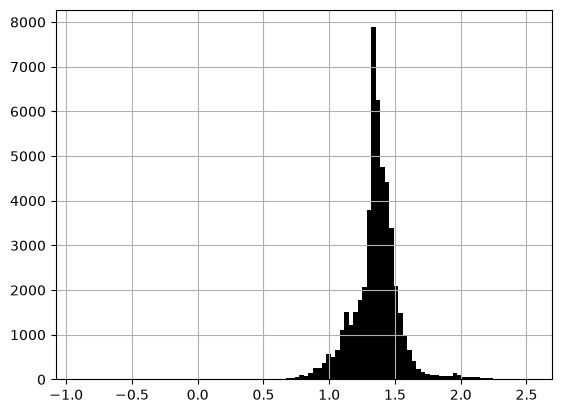

In [27]:
ecg["1"].hist(bins=100, color="black",)

Text(0.5, 1.0, 'Пассажиры')

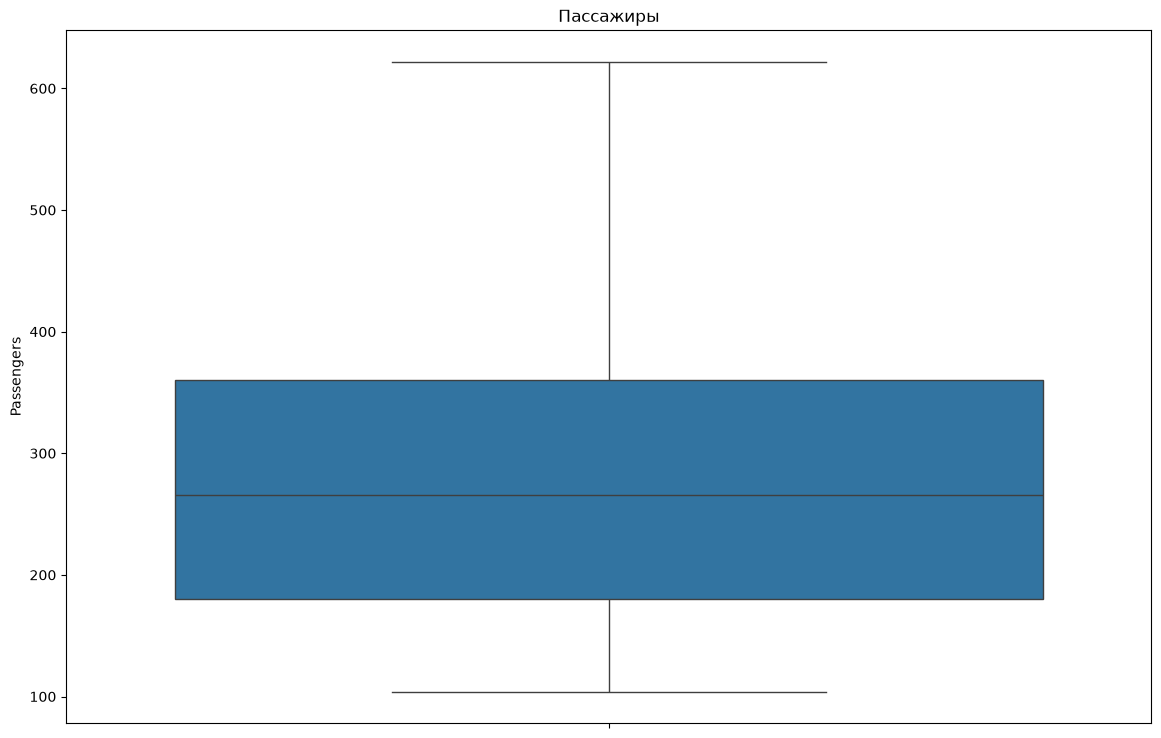

In [28]:
fig = plt.figure(figsize=(14, 9))
 
sns.boxplot(pdf.Passengers).set_title('Пассажиры')

Text(0.5, 1.0, 'ЭКГ')

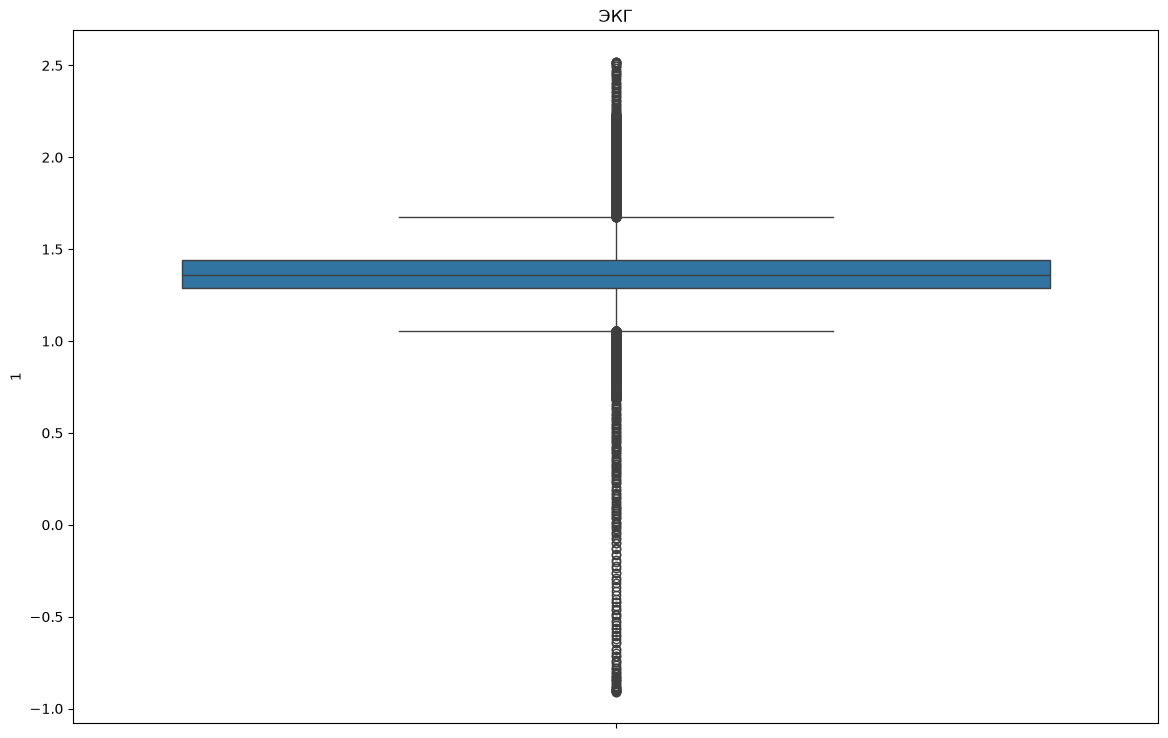

In [29]:
fig = plt.figure(figsize=(14, 9))
ax = sns.boxplot(ecg["1"])
ax.set_title('ЭКГ')

Давайте напишем функцию для автоматического обнаружения выбросов во временном ряду с использованием алгоритма кластеризации из библиотеки scikit-learn: машина векторов поддержки одного класса, она изучает границы распределения (называемые « support ») и, следовательно, может классифицировать любые точки, лежащие за пределами границы, как выбросы.

In [30]:
from sklearn import preprocessing, svm

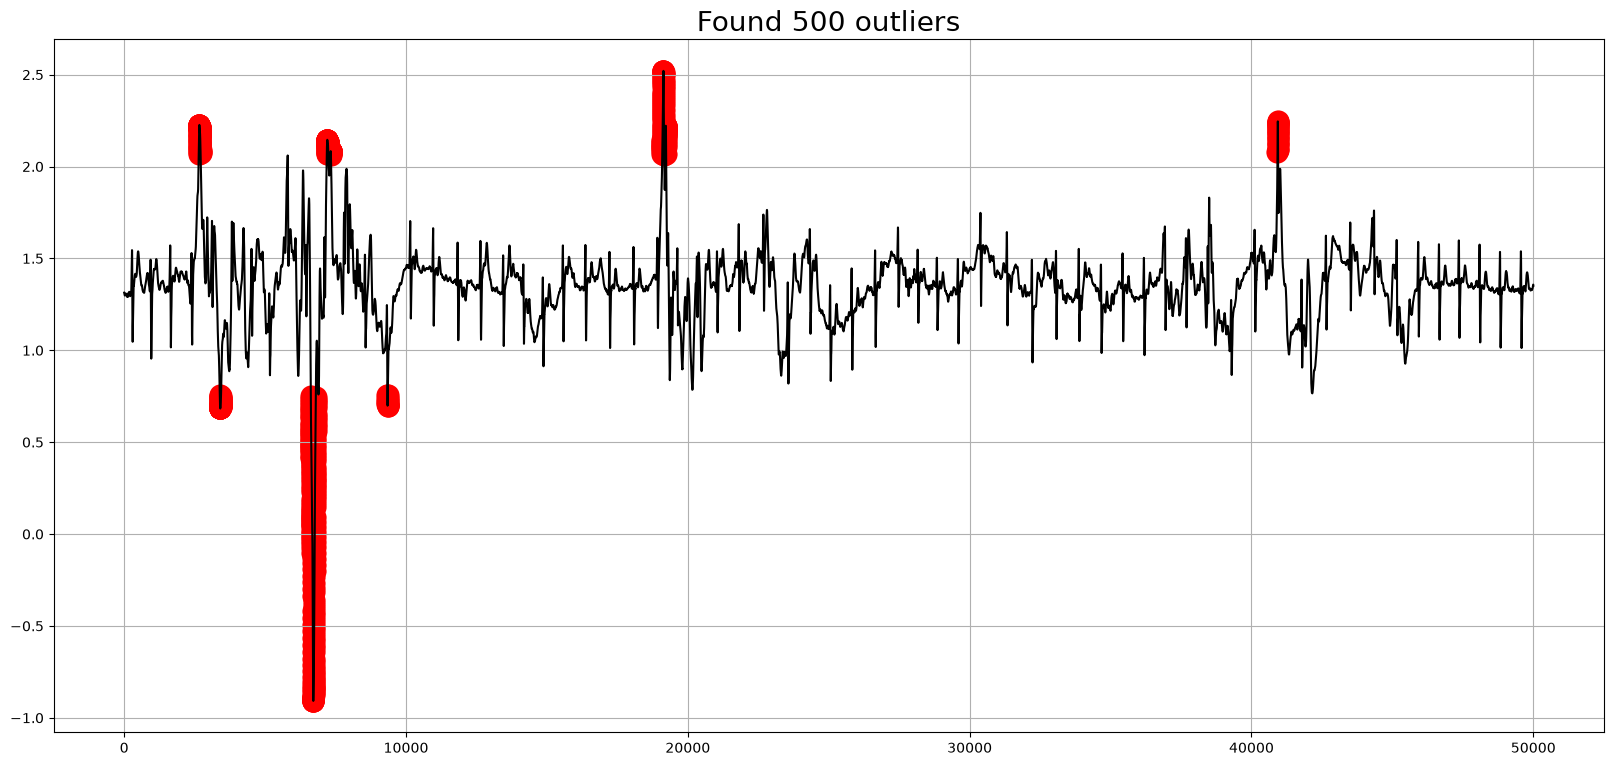

In [31]:
scaler = preprocessing.StandardScaler()
perc = 0.01

local_df = ecg["1"]

ts_scaled = scaler.fit_transform(local_df.values.reshape(-1,1))
model = svm.OneClassSVM(nu=perc, kernel="rbf", gamma=0.01)
model.fit(ts_scaled)
## dtf output
dtf_outliers =local_df.to_frame(name="ts")
dtf_outliers["index"] = range(len(local_df))
dtf_outliers["outlier"] = model.predict(ts_scaled)
dtf_outliers["outlier"] = dtf_outliers["outlier"].apply(lambda
                                                            x: 1 if x==-1 else 0)
## plot
fig, ax = plt.subplots(figsize=(20, 9))
ax.plot(dtf_outliers["index"], dtf_outliers["ts"],
        color="black")
ax.scatter(x=dtf_outliers[dtf_outliers["outlier"]==1]["index"],
           y=dtf_outliers[dtf_outliers["outlier"]==1]['ts'],
           color='red', linewidths=10)
plt.title(f"Found {sum(dtf_outliers['outlier']==1)} outliers", fontdict={'fontsize': 20})
ax.grid(True)
plt.show()

Но что нам делать с выбросами после обнаружения? Здесь нет оптимальной стратегии: прогнозировать временные ряды проще без точек данных, которые значительно отличаются от других наблюдений, но удаление этих точек может глубоко изменить распределение данных. Если вы решили исключить выбросы, наиболее удобный способ их удаления - интерполяция.

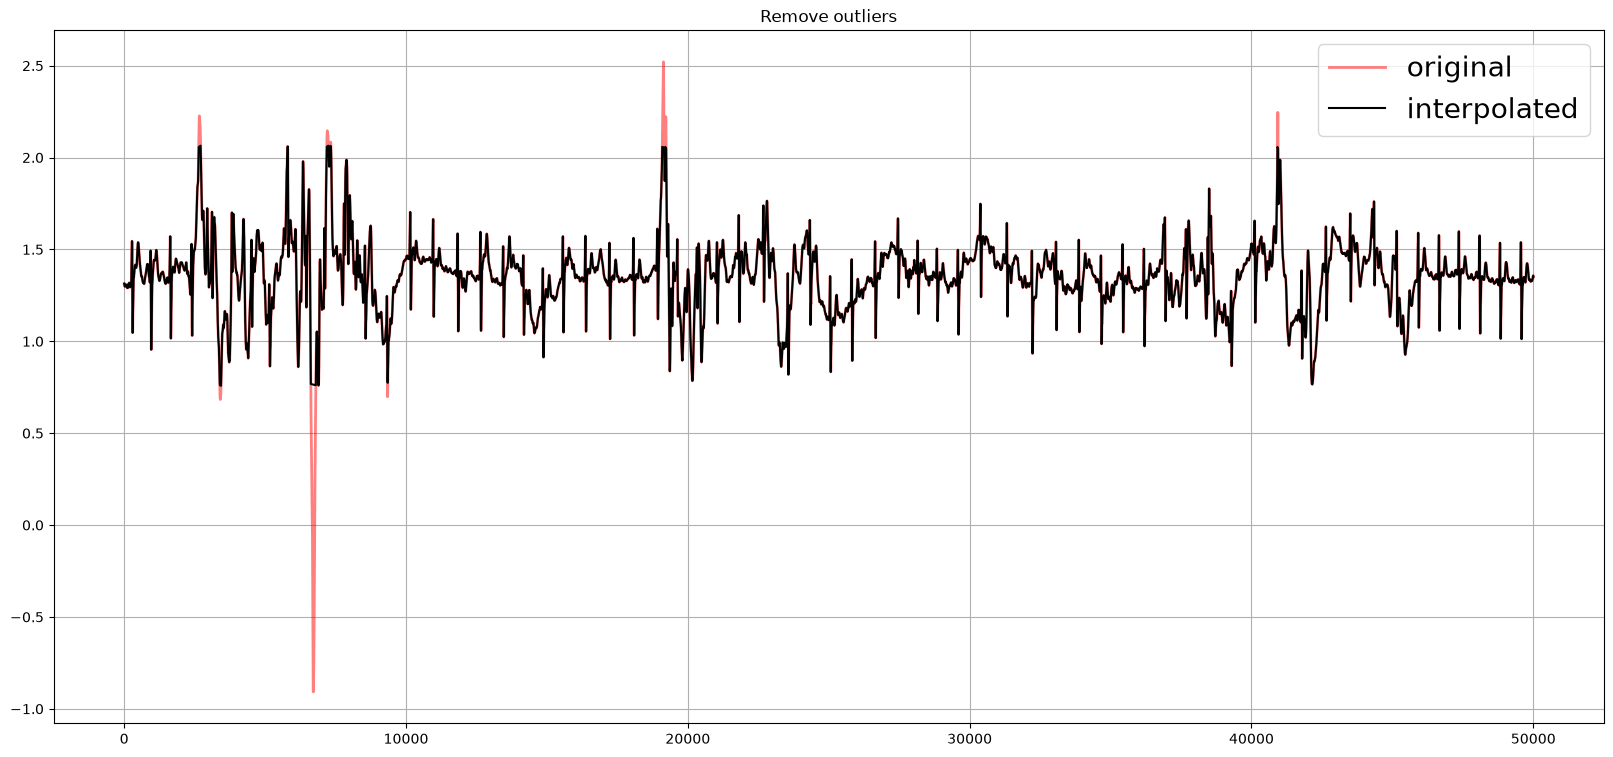

In [32]:
outliers_idx = dtf_outliers[dtf_outliers["outlier"]==1].index

ts_clean = local_df.copy()
ts_clean.loc[outliers_idx] = np.nan
ts_clean = ts_clean.interpolate(method="linear")
ax = local_df.plot(figsize=(20, 9), color="red", alpha=0.5,
             title="Remove outliers", label="original", legend=True, linewidth=2)
ts_clean.plot(ax=ax, grid=True, color="black",
              label="interpolated", legend=True)
plt.legend(fontsize="20")
plt.show()